# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ayda
- **Email:** aydasalzabillah@gmail.com
- **ID Dicoding:** DS284B6X0298

## Menentukan Pertanyaan Bisnis

Konteks: sebuah operator bike sharing (Capital Bikeshare, Washington D.C.) ingin mengatur ketersediaan dan redistribusi sepeda serta merencanakan promosi berdasarkan data historis 2011-2012.

1. **Pada jam berapa puncak penyewaan sepeda terjadi pada hari kerja dibandingkan akhir pekan/hari libur, dan berapa rata-rata penyewaan per jam pada jam puncak tersebut selama 2011-2012**, sehingga tim operasional dapat menjadwalkan redistribusi sepeda tepat sebelum jam puncak?
2. **Berapa persen penurunan rata-rata penyewaan harian pada cuaca berkabut/berawan (kategori 2) dan hujan/salju ringan (kategori 3) dibandingkan cuaca cerah (kategori 1) selama 2011-2012, dan pada rentang suhu berapa penyewaan paling tinggi**, sehingga tim dapat menyesuaikan jumlah sepeda yang disiapkan dan waktu perawatan armada?
3. **Berapa pertumbuhan total penyewaan tahun 2012 dibandingkan 2011, bulan apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah, dan bagaimana proporsi pengguna terdaftar (registered) dibandingkan pengguna kasual (casual)**, sehingga tim pemasaran dapat menentukan waktu kampanye dan target segmen pengguna?

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data
Data dimuat dari dua berkas: `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam).

In [3]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)
day_df.head()

Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi 731 baris (1 Januari 2011 - 31 Desember 2012), `hour.csv` berisi 17.379 baris.
- Kedua tabel memiliki kolom yang sama; `hour.csv` hanya menambah kolom `hr`.
- Nilai `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk ternormalisasi (0-1), dan kategori masih berupa kode angka.

### Assessing Data

In [5]:
print("=== Tipe data day_df ===")
day_df.info()
print()
print("=== Tipe data hour_df ===")
hour_df.info()

=== Tipe data day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== Tipe data hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 

In [6]:
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat day_df      :", day_df.duplicated().sum())
print("Duplikat hour_df     :", hour_df.duplicated().sum())

Missing value day_df : 0
Missing value hour_df: 0
Duplikat day_df      : 0
Duplikat hour_df     : 0


In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Pemeriksaan 1: nilai tidak valid (invalid value) pada kelembapan.** Kelembapan 0% tidak realistis untuk Washington D.C.

In [8]:
print("Hari dengan hum = 0 (day_df):")
display(day_df[day_df["hum"] == 0][["dteday", "hum", "weathersit", "cnt"]])

print("Jam dengan hum = 0 (hour_df):", (hour_df["hum"] == 0).sum())
print("Tanggal-tanggalnya:", list(hour_df.loc[hour_df["hum"] == 0, "dteday"].unique()))

Hari dengan hum = 0 (day_df):


,dteday,hum,weathersit,cnt
68,2011-03-10,0.0,3,623


Jam dengan hum = 0 (hour_df): 22
Tanggal-tanggalnya: ['2011-03-10']


**Pemeriksaan 2: data hilang secara implisit.** Seharusnya ada 24 jam x 731 hari = 17.544 baris pada `hour_df`.

In [9]:
tmp = hour_df.copy()
tmp["dteday"] = pd.to_datetime(tmp["dteday"])
expected = pd.date_range(tmp["dteday"].min(), tmp["dteday"].max() + pd.Timedelta(hours=23), freq="h")
actual = pd.DatetimeIndex(tmp["dteday"] + pd.to_timedelta(tmp["hr"], unit="h"))
missing_hours = expected.difference(actual)

print("Jumlah baris seharusnya:", len(expected))
print("Jumlah baris aktual    :", len(tmp))
print("Jam yang hilang        :", len(missing_hours))
print("Jam hilang terbanyak pada hr:", pd.Series(missing_hours.hour).value_counts().head(5).to_dict())

Jumlah baris seharusnya: 17544
Jumlah baris aktual    : 17379
Jam yang hilang        : 165
Jam hilang terbanyak pada hr: {3: 34, 4: 34, 2: 16, 5: 14, 1: 7}


**Pemeriksaan 3: inkonsistensi label musim.** Readme menyebut `1: springer`, tetapi tanggal pada data menunjukkan hal lain.

In [10]:
tmp_day = day_df.copy()
tmp_day["dteday"] = pd.to_datetime(tmp_day["dteday"])
tmp_day[tmp_day["yr"] == 0].groupby("season")["dteday"].agg(["min", "max"])

,min,max
season,,
1,2011-01-01,2011-12-31
2,2011-03-21,2011-06-20
3,2011-06-21,2011-09-22
4,2011-09-23,2011-12-20


Kode 1 mencakup 1 Januari - 20 Maret (dan 21 Desember - 31 Desember), yaitu **musim dingin**; kode 2 mulai 21 Maret (**semi**), kode 3 mulai 21 Juni (**panas**), dan kode 4 mulai 23 September (**gugur**). Jadi label di Readme tidak sesuai dengan tanggal pada data.

**Pemeriksaan 4: outlier.** Dicek dengan metode IQR pada kolom numerik utama di `day_df`.

cnt        : 0 outlier
casual     : 44 outlier
registered : 0 outlier
windspeed  : 13 outlier
hum        : 2 outlier
temp       : 0 outlier


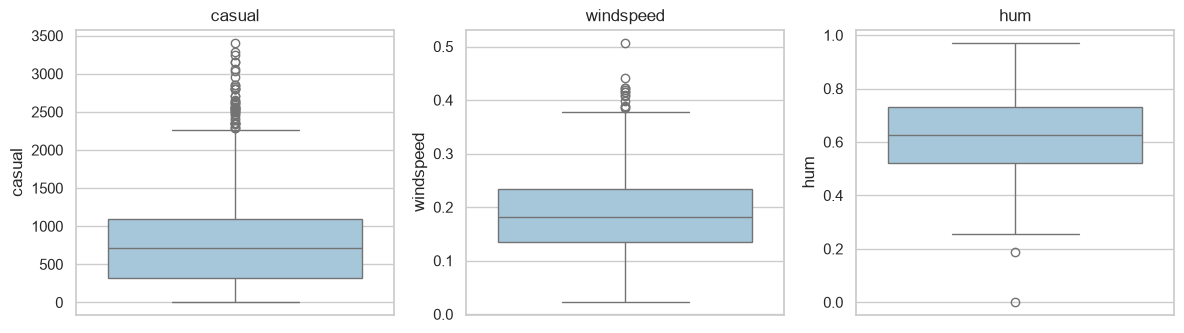

In [11]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

for col in ["cnt", "casual", "registered", "windspeed", "hum", "temp"]:
    print(f"{col:11s}: {count_outliers(day_df[col])} outlier")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, col in zip(ax, ["casual", "windspeed", "hum"]):
    sns.boxplot(y=day_df[col], ax=a, color="#9ecae1")
    a.set_title(col)
plt.tight_layout()
plt.show()

In [12]:
print("Konsistensi cnt = casual + registered (day) :", (day_df["cnt"] == day_df["casual"] + day_df["registered"]).all())
print("Konsistensi cnt = casual + registered (hour):", (hour_df["cnt"] == hour_df["casual"] + hour_df["registered"]).all())
print("weathersit = 4 pada day_df :", (day_df["weathersit"] == 4).sum(), "baris")
print("weathersit = 4 pada hour_df:", (hour_df["weathersit"] == 4).sum(), "baris")

Konsistensi cnt = casual + registered (day) : True
Konsistensi cnt = casual + registered (hour): True
weathersit = 4 pada day_df : 0 baris
weathersit = 4 pada hour_df: 3 baris


**Insight (masalah yang ditemukan dan rencana pembersihan):**

| No | Masalah | Temuan | Tindakan pada Cleaning Data |
|----|---------|--------|-----------------------------|
| 1 | Tipe data tidak sesuai | `dteday` bertipe string | Ubah ke `datetime` |
| 2 | Invalid value | `hum = 0` pada 2011-03-10 (1 hari di `day_df`, 22 jam di `hour_df`) | Ganti dengan `NaN`, lalu isi dengan median kelembapan bulan yang sama |
| 3 | Inconsistent value | Label musim di Readme keliru: kode 1 = musim dingin, 2 = semi, 3 = panas, 4 = gugur | Beri label berdasarkan tanggal sebenarnya |
| 4 | Nilai ternormalisasi dan kode angka | `temp`, `atemp`, `hum`, `windspeed` 0-1; `weathersit`, `weekday`, `yr`, `mnth` berupa kode | Kembalikan ke satuan asli dan beri label |
| 5 | Data hilang implisit | 165 jam tidak ada di `hour_df` (17.379 dari 17.544), terutama pukul 02:00-05:00 yang memang sepi | Tidak diimputasi, hanya didokumentasikan; analisis memakai rata-rata sehingga tidak bias oleh jam yang hilang |
| 6 | Outlier | `casual` dan `windspeed` memiliki outlier IQR | Dipertahankan karena merupakan variasi nyata (mis. akhir pekan cerah), bukan kesalahan data |
| 7 | Kategori langka | `weathersit = 4` hanya 3 jam dan tidak ada di `day_df` | Dipertahankan di data per jam, namun tidak dianalisis secara terpisah |

Tidak ditemukan missing value eksplisit maupun data duplikat.

### Cleaning Data

In [13]:
season_map = {1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"}
weather_map = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
year_map = {0: 2011, 1: 2012}

def clean(df):
    df = df.copy()
    # 1. tipe data
    df["dteday"] = pd.to_datetime(df["dteday"])
    # 2. invalid value: hum = 0 -> NaN -> median bulan yang sama (tahun yang sama)
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df.groupby(["yr", "mnth"])["hum"].transform(lambda s: s.fillna(s.median()))
    # 3. satuan asli
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67
    # 4. label kategori
    df["season_label"] = df["season"].map(season_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["year"] = df["yr"].map(year_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    return df

day_clean = clean(day_df)
hour_clean = clean(hour_df)

print("Sisa hum = 0 (day) :", (day_clean["hum"] == 0).sum())
print("Sisa hum = 0 (hour):", (hour_clean["hum"] == 0).sum())
print("Missing value day  :", day_clean.isna().sum().sum())
print("Missing value hour :", hour_clean.isna().sum().sum())
day_clean.head()

Sisa hum = 0 (day) : 0
Sisa hum = 0 (hour): 0
Missing value day  : 0
Missing value hour : 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_c,atemp_c,hum_pct,windspeed_kmh,season_label,weather_label,weekday_label,year,day_type
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,14.110847,18.18125,80.5833,10.749882,Dingin,Berkabut/Berawan,Sabtu,2011,Akhir Pekan/Libur
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,14.902598,17.68695,69.6087,16.652113,Dingin,Berkabut/Berawan,Minggu,2011,Akhir Pekan/Libur
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,8.050924,9.47025,43.7273,16.636703,Dingin,Cerah,Senin,2011,Hari Kerja
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,8.200000,10.60610,59.0435,10.739832,Dingin,Cerah,Selasa,2011,Hari Kerja
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,9.305237,11.46350,43.6957,12.522300,Dingin,Cerah,Rabu,2011,Hari Kerja


**Insight:**
- Kelembapan 0 pada 2011-03-10 diganti dengan median bulan Maret 2011.
- Seluruh kolom cuaca kini dalam satuan asli (°C, %, km/jam) dan kategori sudah berlabel sehingga mudah dibaca pada visualisasi.

## Exploratory Data Analysis (EDA)

### Eksplorasi Gambaran Umum

In [14]:
day_clean[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(2)

,cnt,casual,registered,temp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,4504.35,848.18,3656.17,20.31,62.87,12.76
std,1937.21,686.62,1560.26,7.51,14.05,5.19
min,22.00,2.00,20.00,2.42,18.79,1.50
25%,3152.00,315.50,2497.00,13.82,52.10,9.04
50%,4548.00,713.00,3662.00,20.43,62.67,12.13
75%,5956.00,1096.00,4776.50,26.87,73.02,15.63
max,8714.00,3410.00,6946.00,35.33,97.25,34.00


In [15]:
total = day_clean["cnt"].sum()
print(f"Total penyewaan 2011-2012          : {total:,}")
print(f"Rata-rata penyewaan per hari       : {day_clean['cnt'].mean():,.0f}")
print(f"Porsi pengguna registered          : {day_clean['registered'].sum() / total:.1%}")
print(f"Porsi pengguna casual              : {day_clean['casual'].sum() / total:.1%}")

Total penyewaan 2011-2012          : 3,292,679
Rata-rata penyewaan per hari       : 4,504
Porsi pengguna registered          : 81.2%
Porsi pengguna casual              : 18.8%


### Eksplorasi Pertanyaan 1: Pola Penyewaan per Jam

In [16]:
hourly = (hour_clean.groupby(["day_type", "hr"])["cnt"].mean().round(1).unstack(0))
hourly

day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
0,90.8,36.8
1,69.5,16.6
2,53.2,8.7
3,25.8,4.9
4,8.3,5.4
5,8.7,24.9
6,18.7,102.5
7,43.4,290.6
8,105.7,477.0


In [17]:
for tipe in ["Hari Kerja", "Akhir Pekan/Libur"]:
    top = hourly[tipe].sort_values(ascending=False).head(3)
    print(tipe, "-> 3 jam teratas:", {f"{h:02d}:00": v for h, v in top.items()})

Hari Kerja -> 3 jam teratas: {'17:00': 525.3, '18:00': 492.2, '08:00': 477.0}
Akhir Pekan/Libur -> 3 jam teratas: {'13:00': 372.7, '12:00': 366.3, '14:00': 364.6}


In [18]:
# Perbandingan pengguna casual vs registered per jenis hari
hour_clean.groupby("day_type")[["casual", "registered"]].mean().round(1)

,casual,registered
day_type,,
Akhir Pekan/Libur,57.4,124.0
Hari Kerja,25.6,167.6


### Eksplorasi Pertanyaan 2: Pengaruh Cuaca dan Suhu

In [19]:
weather_summary = (day_clean.groupby("weather_label")["cnt"]
                   .agg(jumlah_hari="count", rata_rata="mean", median="median")
                   .round(0).sort_values("rata_rata", ascending=False))
weather_summary

,jumlah_hari,rata_rata,median
weather_label,,,
Cerah,463,4877.0,4844.0
Berkabut/Berawan,247,4036.0,4040.0
Hujan/Salju Ringan,21,1803.0,1817.0


In [20]:
base = weather_summary.loc["Cerah", "rata_rata"]
for w in ["Berkabut/Berawan", "Hujan/Salju Ringan"]:
    drop = (weather_summary.loc[w, "rata_rata"] - base) / base
    print(f"{w:20s}: {drop:+.1%} dibanding hari cerah")

Berkabut/Berawan    : -17.2% dibanding hari cerah
Hujan/Salju Ringan  : -63.0% dibanding hari cerah


In [21]:
day_clean.groupby("season_label")["cnt"].mean().round(0).sort_values(ascending=False)

season_label
Panas     5644.0
Semi      4992.0
Gugur     4728.0
Dingin    2604.0
Name: cnt, dtype: float64

In [22]:
# Korelasi antara kondisi cuaca numerik dan jumlah penyewaan
day_clean[["cnt", "temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].corr().round(2)

,cnt,temp_c,atemp_c,hum_pct,windspeed_kmh
cnt,1.00,0.63,0.63,-0.11,-0.23
temp_c,0.63,1.00,0.99,0.13,-0.16
atemp_c,0.63,0.99,1.00,0.14,-0.18
hum_pct,-0.11,0.13,0.14,1.00,-0.25
windspeed_kmh,-0.23,-0.16,-0.18,-0.25,1.00


### Eksplorasi Pertanyaan 3: Pertumbuhan dan Tren Bulanan

In [23]:
yearly = day_clean.groupby("year")[["cnt", "casual", "registered"]].sum()
yearly["pertumbuhan_cnt_vs_2011"] = yearly["cnt"].pct_change()
yearly

,cnt,casual,registered,pertumbuhan_cnt_vs_2011
year,,,,
2011,1243103,247252,995851,NaN
2012,2049576,372765,1676811,0.648758


In [24]:
monthly = day_clean.groupby(["year", "mnth"])["cnt"].mean().unstack(0).round(0)
monthly["gabungan"] = day_clean.groupby("mnth")["cnt"].mean().round(0)
monthly

year,2011,2012,gabungan
mnth,,,
1,1232.0,3121.0,2176.0
2,1722.0,3556.0,2655.0
3,2066.0,5319.0,3692.0
4,3162.0,5807.0,4485.0
5,4381.0,6318.0,5350.0
6,4784.0,6761.0,5772.0
7,4559.0,6568.0,5564.0
8,4409.0,6919.0,5664.0
9,4247.0,7286.0,5767.0


In [25]:
print("Bulan tertinggi:", monthly["gabungan"].idxmax(), "->", monthly["gabungan"].max())
print("Bulan terendah :", monthly["gabungan"].idxmin(), "->", monthly["gabungan"].min())

Bulan tertinggi: 6 -> 5772.0
Bulan terendah : 1 -> 2176.0


**Insight EDA:**
- Hari kerja memiliki dua puncak jelas (pagi sekitar pukul 08:00 dan sore sekitar pukul 17:00-18:00), sedangkan akhir pekan/libur hanya memiliki satu puncak landai pada tengah hari.
- Rata-rata penyewaan harian turun pada cuaca berkabut dan turun tajam pada hujan/salju ringan dibanding hari cerah.
- Total penyewaan tahun 2012 jauh lebih tinggi dibanding 2011, dan pola musiman terlihat dengan puncak pada pertengahan tahun serta titik terendah pada awal tahun.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan terjadi pada hari kerja dibandingkan akhir pekan/libur?

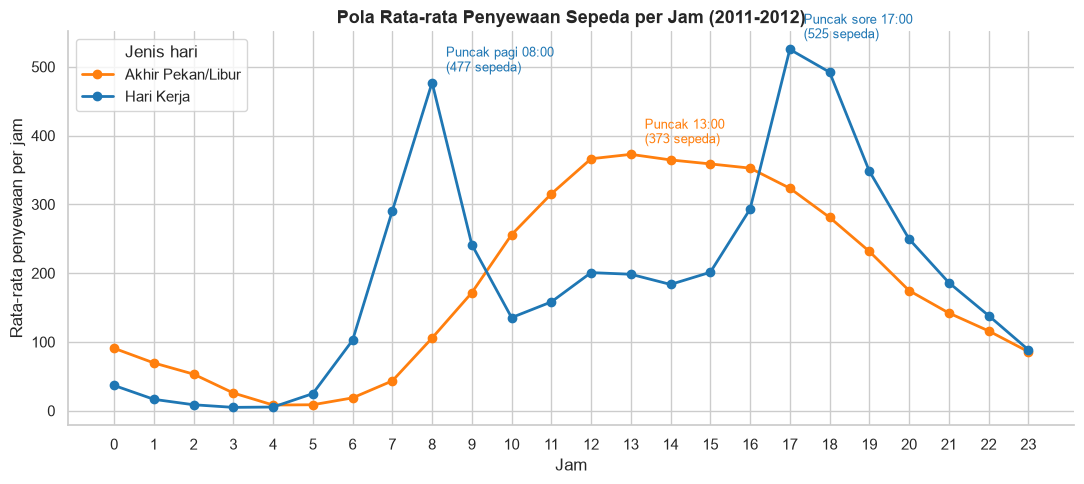

In [26]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}
for tipe in hourly.columns:
    ax.plot(hourly.index, hourly[tipe], marker="o", linewidth=2, label=tipe, color=colors[tipe])
pagi = hourly.loc[6:10, "Hari Kerja"]
sore = hourly.loc[15:20, "Hari Kerja"]
for s, lbl in [(pagi, "Puncak pagi"), (sore, "Puncak sore")]:
    ax.annotate(f"{lbl} {s.idxmax():02d}:00\n({s.max():.0f} sepeda)", (s.idxmax(), s.max()),
                textcoords="offset points", xytext=(10, 8), fontsize=9, color=colors["Hari Kerja"])
we = hourly["Akhir Pekan/Libur"]
ax.annotate(f"Puncak {we.idxmax():02d}:00\n({we.max():.0f} sepeda)", (we.idxmax(), we.max()),
            textcoords="offset points", xytext=(10, 8), fontsize=9, color=colors["Akhir Pekan/Libur"])
ax.set_xticks(range(0, 24))
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Pola Rata-rata Penyewaan Sepeda per Jam (2011-2012)", fontsize=13, fontweight="bold")
ax.legend(title="Jenis hari")
sns.despine()
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 1:**
- Pada **hari kerja** terdapat dua puncak: pagi pukul **08:00** (rata-rata sekitar 477 sepeda/jam) dan sore pukul **17:00** (sekitar 525 sepeda/jam). Pola ini khas komuter berangkat dan pulang kerja.
- Pada **akhir pekan/libur** hanya ada satu puncak landai pukul **13:00** (sekitar 373 sepeda/jam) yang bertahan sepanjang siang, menandakan penggunaan rekreasi.

### Pertanyaan 2: Seberapa besar penurunan penyewaan akibat cuaca, dan pada suhu berapa penyewaan tertinggi?

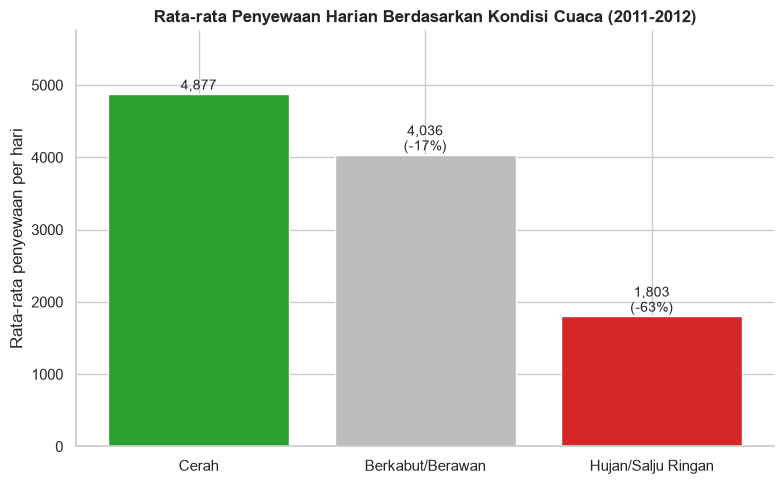

In [27]:
order = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]
avg_weather = day_clean.groupby("weather_label")["cnt"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(order, avg_weather.values, color=["#2ca02c", "#bdbdbd", "#d62728"])
base = avg_weather["Cerah"]
for b, v, name in zip(bars, avg_weather.values, order):
    label = f"{v:,.0f}" if name == "Cerah" else f"{v:,.0f}\n({(v-base)/base:+.0%})"
    ax.text(b.get_x() + b.get_width() / 2, v + 60, label, ha="center", fontsize=10)
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_title("Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca (2011-2012)", fontsize=12, fontweight="bold")
ax.set_ylim(0, avg_weather.max() * 1.18)
sns.despine()
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 2 (bagian cuaca):**
- Dibanding hari cerah (rata-rata sekitar 4.877 sepeda/hari), penyewaan **turun sekitar 17%** saat berkabut/berawan dan **turun sekitar 63%** saat hujan/salju ringan.
- Hujan/salju ringan menjadi faktor penekan terbesar, jauh lebih besar daripada berkabut.

### Analisis Lanjutan: Manual Grouping dan Binning
Tujuan: mengelompokkan data ke kategori yang bermakna secara bisnis **tanpa algoritma machine learning**, yaitu:
1. **Binning suhu** (`pd.cut`) ke kategori Dingin, Sejuk, Hangat, Panas untuk mengetahui rentang suhu ideal penyewaan.
2. **Manual grouping jam** ke periode hari (Dini Hari, Pagi, Siang, Sore, Malam) untuk perencanaan shift operasional.
3. **Binning permintaan harian** (`pd.qcut`) ke Rendah, Sedang, Tinggi untuk melihat komposisi tingkat permintaan per musim.

In [28]:
# 1. Binning suhu
temp_bins = [-np.inf, 10, 20, 30, np.inf]
temp_labels = ["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"]
day_clean["temp_category"] = pd.cut(day_clean["temp_c"], bins=temp_bins, labels=temp_labels, right=False)
hour_clean["temp_category"] = pd.cut(hour_clean["temp_c"], bins=temp_bins, labels=temp_labels, right=False)

# 2. Manual grouping jam
def time_of_day(h):
    if h < 6:   return "Dini Hari (00-05)"
    if h < 11:  return "Pagi (06-10)"
    if h < 15:  return "Siang (11-14)"
    if h < 19:  return "Sore (15-18)"
    return "Malam (19-23)"
hour_clean["time_category"] = hour_clean["hr"].apply(time_of_day)

# 3. Binning permintaan harian (tiga kuantil)
day_clean["demand_category"] = pd.qcut(day_clean["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"])

temp_summary = day_clean.groupby("temp_category", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata="mean").round(0)
temp_summary

,jumlah_hari,rata_rata
temp_category,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


In [29]:
time_order = ["Dini Hari (00-05)", "Pagi (06-10)", "Siang (11-14)", "Sore (15-18)", "Malam (19-23)"]
time_summary = (hour_clean.groupby(["time_category", "day_type"])["cnt"].mean()
                .unstack().reindex(time_order).round(0))
time_summary

day_type,Akhir Pekan/Libur,Hari Kerja
time_category,,
Dini Hari (00-05),43.0,16.0
Pagi (06-10),119.0,249.0
Siang (11-14),355.0,185.0
Sore (15-18),329.0,378.0
Malam (19-23),150.0,202.0


In [30]:
pd.crosstab(day_clean["season_label"], day_clean["demand_category"], normalize="index").round(2)

demand_category,Rendah,Sedang,Tinggi
season_label,,,
Dingin,0.77,0.18,0.04
Gugur,0.30,0.34,0.35
Panas,0.07,0.42,0.51
Semi,0.20,0.39,0.41


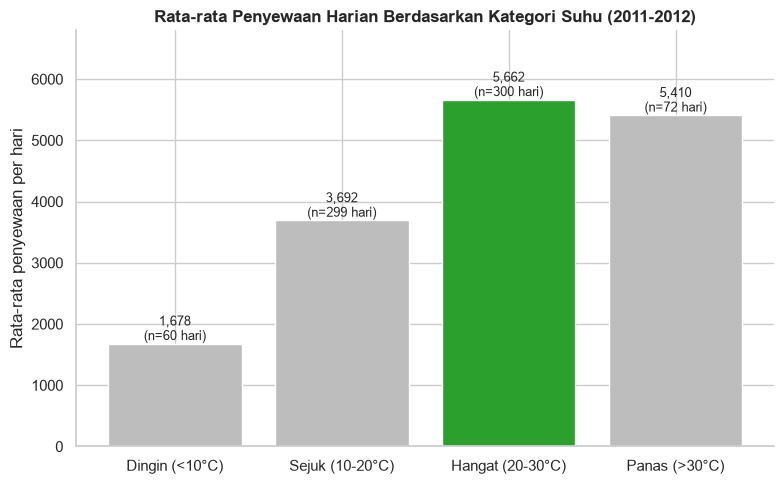

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
vals = temp_summary["rata_rata"]
colors_t = ["#bdbdbd"] * len(vals)
colors_t[int(np.argmax(vals.values))] = "#2ca02c"
bars = ax.bar(vals.index.astype(str), vals.values, color=colors_t)
for b, v, n in zip(bars, vals.values, temp_summary["jumlah_hari"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,.0f}\n(n={n} hari)", ha="center", fontsize=9)
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_title("Rata-rata Penyewaan Harian Berdasarkan Kategori Suhu (2011-2012)", fontsize=12, fontweight="bold")
ax.set_ylim(0, vals.max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

**Kesimpulan Pertanyaan 2 (bagian suhu):**
- Penyewaan tertinggi terjadi pada suhu **hangat (20-30°C)**, sedangkan suhu dingin (<10°C) memiliki rata-rata terendah.
- Kategori panas (>30°C) sudah mulai menurun dibanding kategori hangat, tetapi jumlah harinya sedikit sehingga perlu hati-hati menafsirkannya.
- Dengan manual grouping jam, periode **Sore (15-18)** pada hari kerja dan **Siang (11-14)** pada akhir pekan memiliki rata-rata tertinggi; periode **Dini Hari** paling sepi di kedua jenis hari.

### Pertanyaan 3: Pertumbuhan 2012 vs 2011, bulan puncak/terendah, dan komposisi pengguna

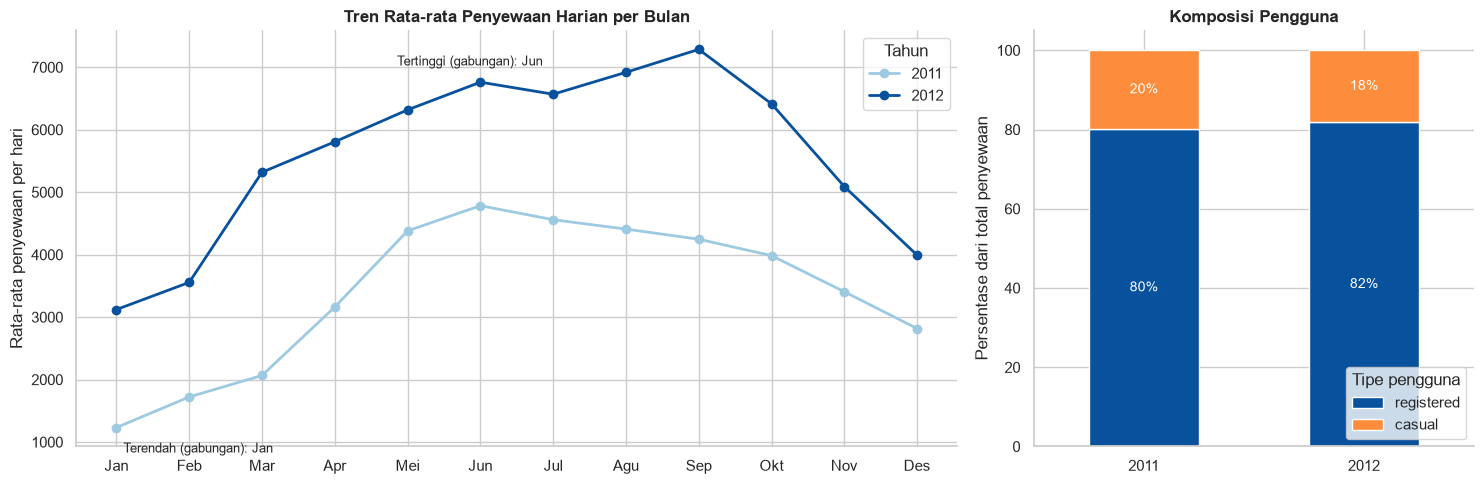

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

# (a) tren bulanan per tahun
month_names = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
for yr, col in zip([2011, 2012], ["#9ecae1", "#08519c"]):
    axes[0].plot(range(1, 13), monthly[yr], marker="o", linewidth=2, label=str(yr), color=col)
peak_m, low_m = int(monthly["gabungan"].idxmax()), int(monthly["gabungan"].idxmin())
axes[0].annotate(f"Tertinggi (gabungan): {month_names[peak_m-1]}", (peak_m, monthly[2012][peak_m]),
                 textcoords="offset points", xytext=(-60, 12), fontsize=9)
axes[0].annotate(f"Terendah (gabungan): {month_names[low_m-1]}", (low_m, monthly[2011][low_m]),
                 textcoords="offset points", xytext=(5, -18), fontsize=9)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_title("Tren Rata-rata Penyewaan Harian per Bulan", fontsize=12, fontweight="bold")
axes[0].legend(title="Tahun")

# (b) komposisi pengguna per tahun
comp = yearly[["registered", "casual"]].div(yearly["cnt"], axis=0) * 100
comp.plot(kind="bar", stacked=True, ax=axes[1], color=["#08519c", "#fd8d3c"], rot=0)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
axes[1].set_ylabel("Persentase dari total penyewaan")
axes[1].set_xlabel("")
axes[1].set_title("Komposisi Pengguna", fontsize=12, fontweight="bold")
axes[1].legend(title="Tipe pengguna", loc="lower right")
sns.despine()
plt.tight_layout()
plt.show()

In [33]:
g = yearly.loc[2012, "cnt"] / yearly.loc[2011, "cnt"] - 1
print(f"Total 2011: {yearly.loc[2011, 'cnt']:,} | Total 2012: {yearly.loc[2012, 'cnt']:,} | Pertumbuhan: {g:.1%}")
print("Pertumbuhan registered:", f"{yearly.loc[2012,'registered']/yearly.loc[2011,'registered']-1:.1%}")
print("Pertumbuhan casual    :", f"{yearly.loc[2012,'casual']/yearly.loc[2011,'casual']-1:.1%}")

Total 2011: 1,243,103 | Total 2012: 2,049,576 | Pertumbuhan: 64.9%
Pertumbuhan registered: 68.4%
Pertumbuhan casual    : 50.8%


**Kesimpulan Pertanyaan 3:**
- Total penyewaan 2012 (2.049.576) **tumbuh sekitar 64,9%** dibanding 2011 (1.243.103).
- Rata-rata penyewaan harian gabungan tertinggi ada pada **Juni** dan terendah pada **Januari**; Mei sampai September konsisten tinggi, sedangkan Desember sampai Februari rendah.
- Pengguna **registered** mendominasi (sekitar 81% dari total) dan porsinya naik dari sekitar 80% (2011) menjadi sekitar 82% (2012) karena registered tumbuh 68,4% sedangkan casual 50,8%. Pengguna casual (sekitar 19%) masih menjadi peluang konversi menjadi anggota.

## Conclusion

- **Pertanyaan 1:** Hari kerja memiliki dua puncak (08:00 dan 17:00) yang mencerminkan pola komuter, sedangkan akhir pekan/libur hanya memiliki satu puncak landai sekitar 13:00 yang mencerminkan pola rekreasi.
- **Pertanyaan 2:** Cuaca sangat memengaruhi penyewaan: turun sekitar 17% saat berkabut/berawan dan sekitar 63% saat hujan/salju ringan dibanding cuaca cerah. Penyewaan tertinggi terjadi pada suhu 20-30°C.
- **Pertanyaan 3:** Penyewaan tumbuh sekitar 65% dari 2011 ke 2012 dengan pola musiman yang kuat (puncak pertengahan tahun, terendah awal tahun), dan pengguna registered mendominasi sekitar 81% dari total.

### Rekomendasi (Action Item)
1. **Redistribusi sepeda:** Jadwalkan pemindahan sepeda ke stasiun area perkantoran/transit sebelum **07:00** dan **16:00** pada hari kerja; pada akhir pekan pusatkan ketersediaan di area rekreasi sebelum **11:00**.
2. **Perawatan armada:** Gunakan jam **dini hari (00:00-05:00)** dan hari berprakiraan hujan/salju untuk perawatan, karena permintaan terendah.
3. **Kesiapan cuaca:** Gunakan prakiraan cuaca untuk menyesuaikan jumlah sepeda yang disebar; kurangi armada aktif saat prakiraan hujan dan siapkan stok penuh saat cerah bersuhu 20-30°C.
4. **Pemasaran:** Fokuskan kampanye konversi pengguna casual menjadi anggota pada **Mei-September** saat permintaan tinggi; siapkan promo langganan di **Desember-Februari** untuk menahan penurunan musiman.

## Ekspor Data untuk Dashboard

In [34]:
hour_clean.to_csv("dashboard/main_data.csv", index=False)
day_clean.to_csv("dashboard/day_clean.csv", index=False)
print("main_data.csv :", hour_clean.shape)
print("day_clean.csv :", day_clean.shape)

main_data.csv : (17379, 28)
day_clean.csv : (731, 27)
